# Assignment #2 (demo). Analyzing cardiovascular disease data

**mlcourse.ai – Open Machine Learning Course**

Task source: [mlcourse.ai](https://mlcourse.ai/book/topic02/assignment02_analyzing_cardiovascular_desease_data.html), authors Ilya Baryshnikov, Maxim Uvarov, Yury Kashnitsky, CC BY-NC-SA 4.0.

**Problem**

Predict the presence or absence of cardiovascular disease (CVD) using the patient examination results.

**Data description**

There are 3 types of input features:

- *Objective*: factual information;
- *Examination*: results of medical examination;
- *Subjective*: information given by the patient.

| Feature | Variable Type | Variable | Value Type |
|---------|---------------|----------|------------|
| Age | Objective Feature | age | int (days) |
| Height | Objective Feature | height | int (cm) |
| Weight | Objective Feature | weight | float (kg) |
| Gender | Objective Feature | gender | categorical code |
| Systolic blood pressure | Examination Feature | ap_hi | int |
| Diastolic blood pressure | Examination Feature | ap_lo | int |
| Cholesterol | Examination Feature | cholesterol | 1: normal, 2: above normal, 3: well above normal |
| Glucose | Examination Feature | gluc | 1: normal, 2: above normal, 3: well above normal |
| Smoking | Subjective Feature | smoke | binary |
| Alcohol intake | Subjective Feature | alco | binary |
| Physical activity | Subjective Feature | active | binary |
| Presence or absence of cardiovascular disease | Target Variable | cardio | binary |

All of the dataset values were collected at the moment of medical examination.

## Part 1. Preliminary data analysis

In [1]:
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker

sns.set()
%matplotlib inline
%config InlineBackend.figure_format = "retina"
warnings.filterwarnings("ignore")

In [2]:
sns.set_context("notebook", font_scale=1.5, rc={"figure.figsize": (11, 8), "axes.titlesize": 18})
matplotlib.rcParams["figure.figsize"] = 11, 8

In [3]:
DATA_PATH = "https://raw.githubusercontent.com/Yorko/mlcourse.ai/main/data/"
df = pd.read_csv(DATA_PATH + "mlbootcamp5_train.csv", sep=";")
print("Dataset size: ", df.shape)
df.head()

Dataset size:  (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


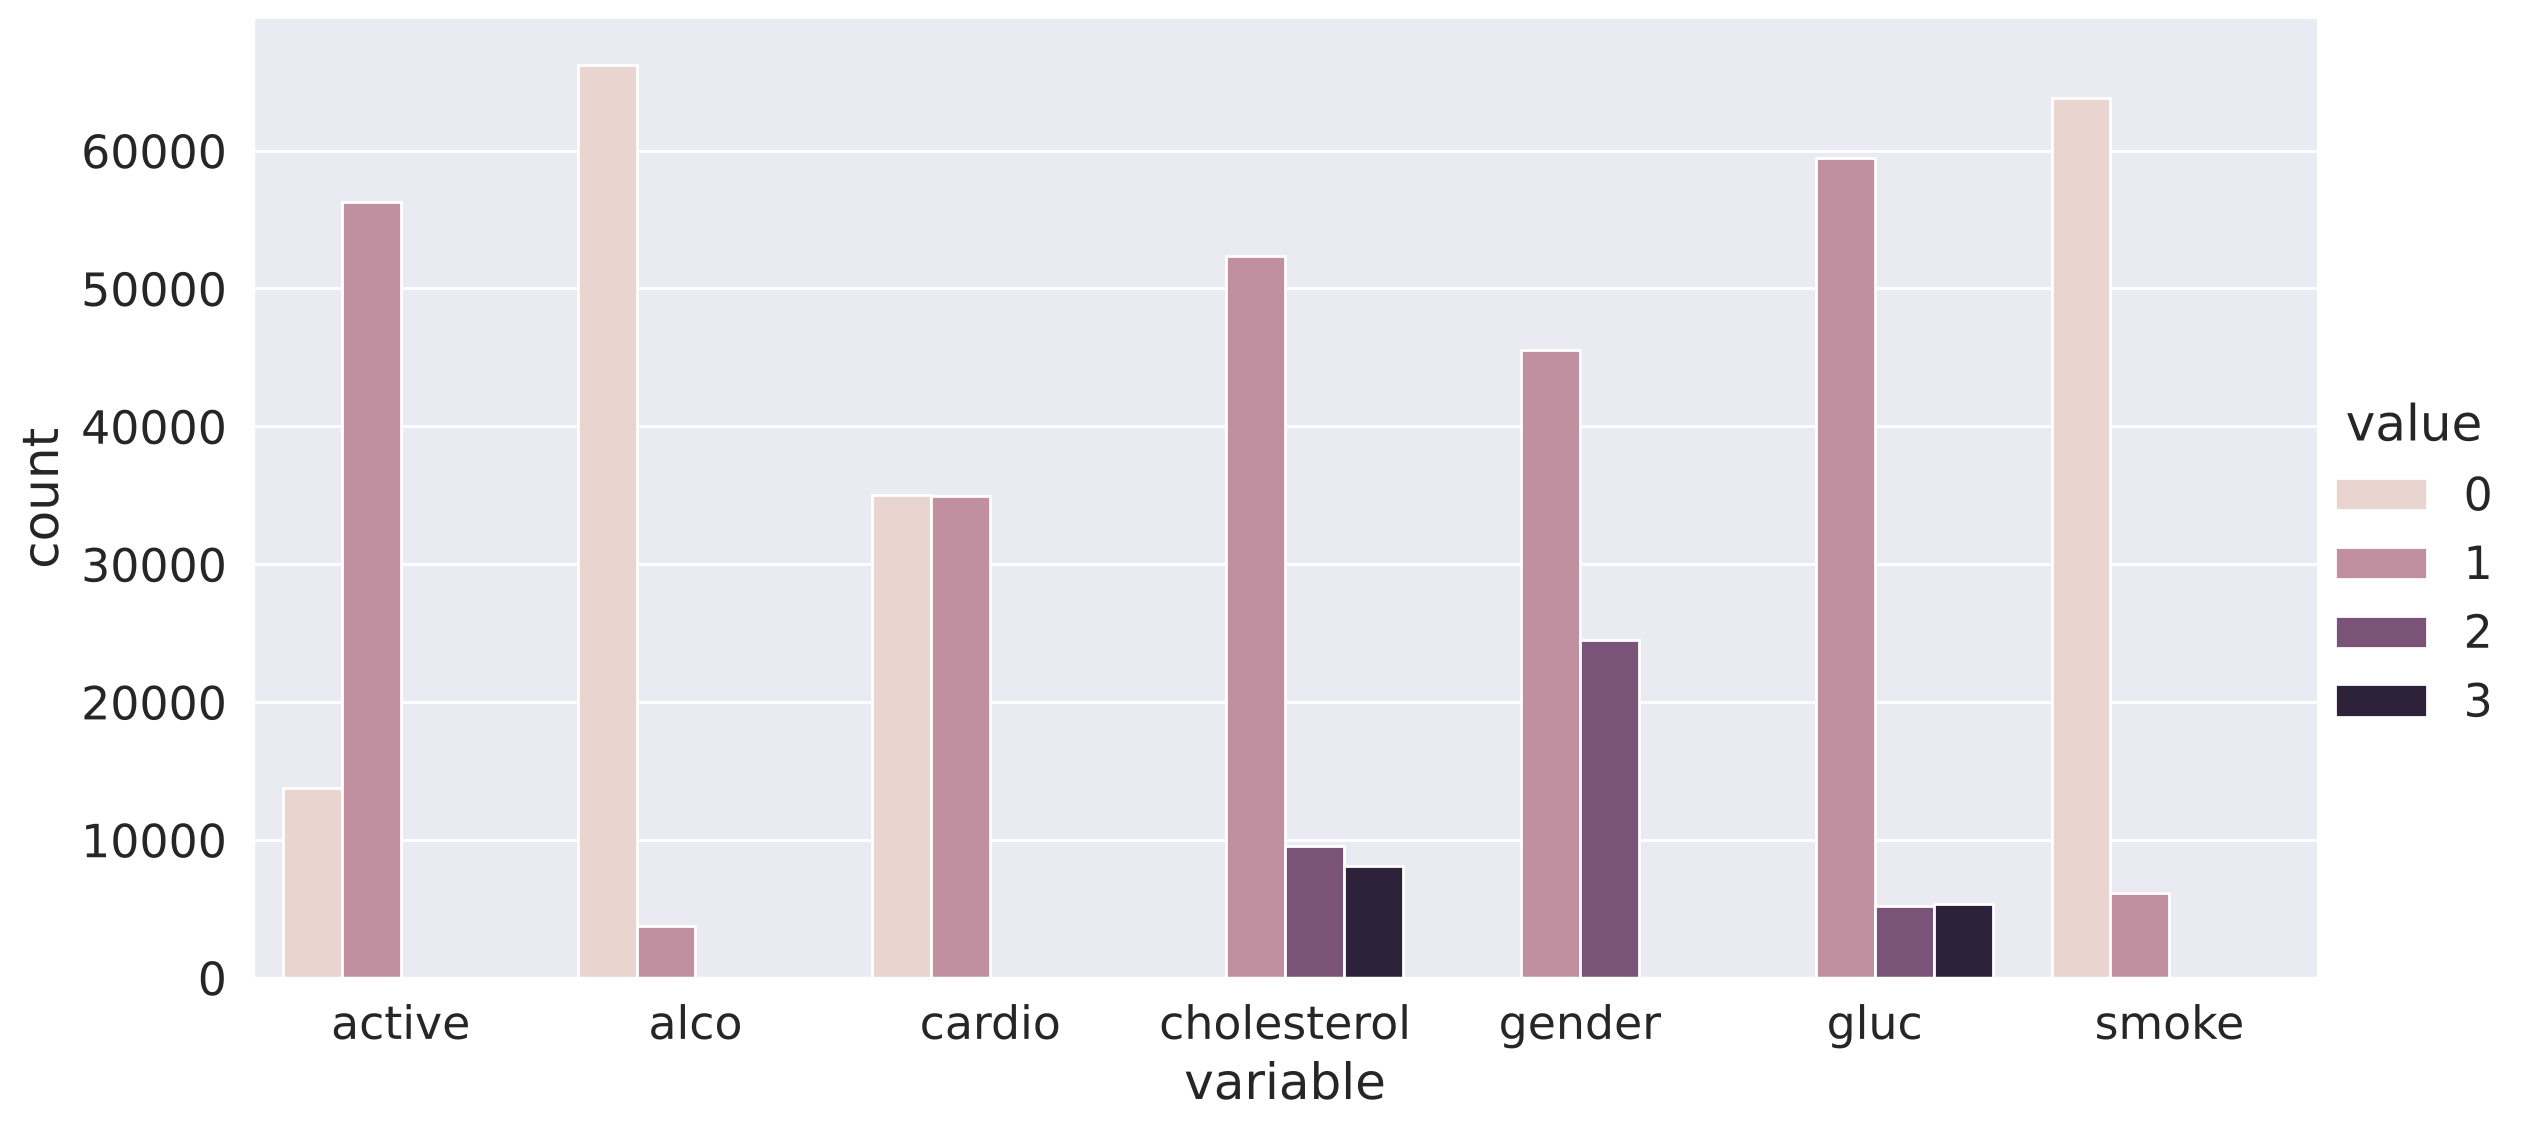

In [4]:
df_uniques = pd.melt(frame=df, value_vars=["gender", "cholesterol", "gluc", "smoke", "alco", "active", "cardio"])
df_uniques = pd.DataFrame(df_uniques.groupby(["variable", "value"])["value"].count()).rename(columns={"value": "count"}).reset_index()
sns.catplot(x="variable", y="count", hue="value", data=df_uniques, kind="bar", height=6, aspect=2);

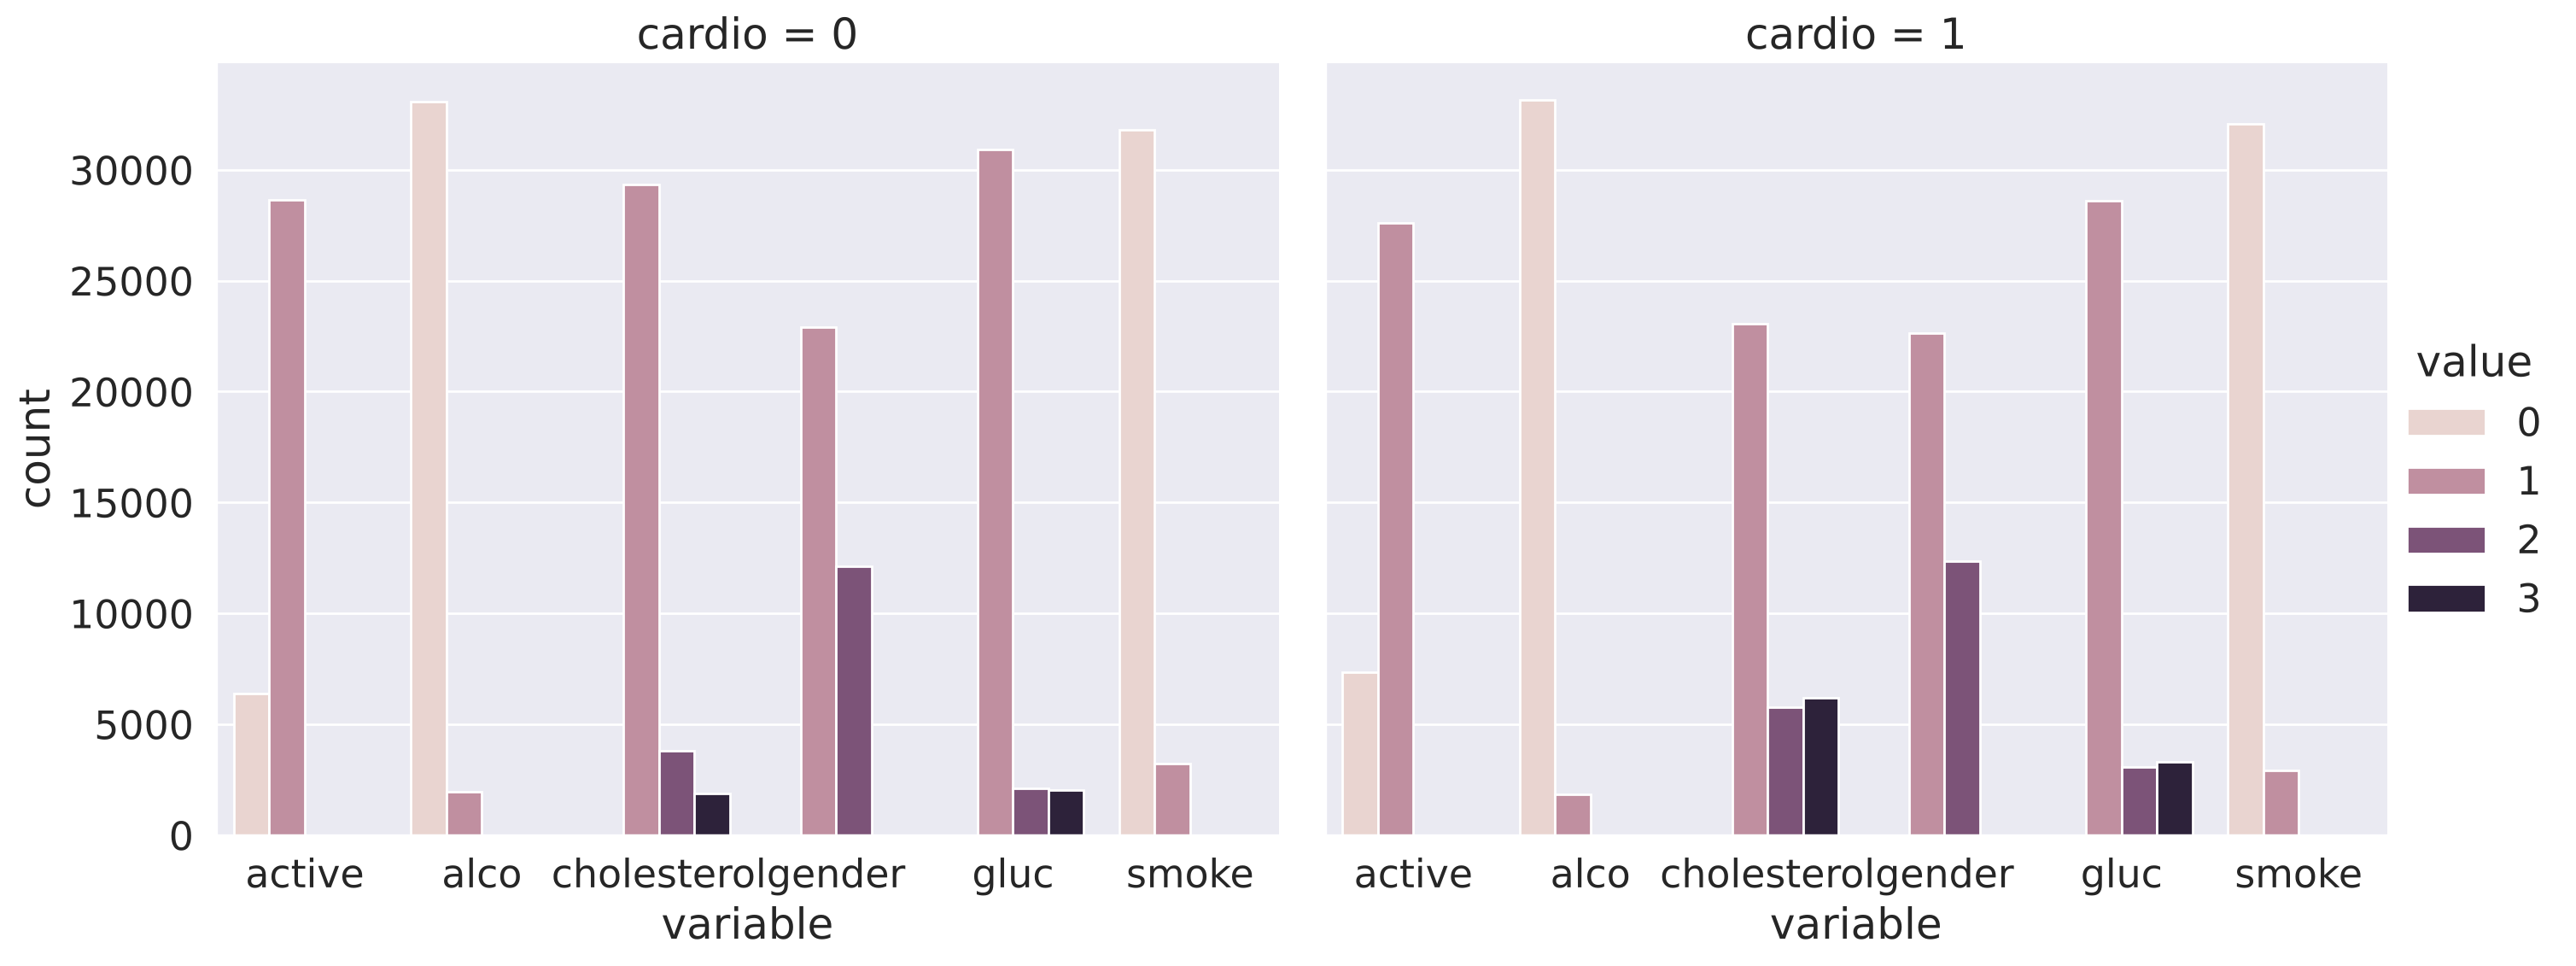

In [5]:
df_uniques = pd.melt(frame=df, value_vars=["gender", "cholesterol", "gluc", "smoke", "alco", "active"], id_vars=["cardio"])
df_uniques = pd.DataFrame(df_uniques.groupby(["variable", "value", "cardio"])["value"].count()).rename(columns={"value": "count"}).reset_index()
sns.catplot(x="variable", y="count", hue="value", col="cardio", data=df_uniques, kind="bar", height=6, aspect=1.2);

In [6]:
for c in df.columns:
    n = df[c].nunique()
    print(c)
    if n <= 3:
        print(n, sorted(df[c].value_counts().to_dict().items()))
    else:
        print(n)
    print(10 * "-")

id
70000
----------
age
8076
----------
gender
2 [(1, 45530), (2, 24470)]
----------
height
109
----------
weight
287
----------
ap_hi
153
----------
ap_lo
157
----------
cholesterol
3 [(1, 52385), (2, 9549), (3, 8066)]
----------
gluc
3 [(1, 59479), (2, 5190), (3, 5331)]
----------
smoke
2 [(0, 63831), (1, 6169)]
----------
alco
2 [(0, 66236), (1, 3764)]
----------
active
2 [(0, 13739), (1, 56261)]
----------
cardio
2 [(0, 35021), (1, 34979)]
----------


### 1.1. Basic observations

**Question 1.1. (1 point). How many men and women are present in this dataset? Values of the `gender` feature were not given (whether "1" stands for women or for men) – figure this out by looking analyzing height, making the assumption that men are taller on average.**

1. 45530 women and 24470 men
2. 45530 men and 24470 women
3. 45470 women and 24530 men
4. 45470 men and 24530 women

In [7]:
df.groupby("gender")["height"].mean()

gender
1    161.355612
2    169.947895
Name: height, dtype: float64

In [8]:
df["gender"].value_counts()

gender
1    45530
2    24470
Name: count, dtype: int64

**Question 1.2. (1 point). Who more often report consuming alcohol – men or women?**

1. women
2. men

In [9]:
df.groupby("gender")["alco"].mean()

gender
1    0.025500
2    0.106375
Name: alco, dtype: float64

**Question 1.3. (1 point). What's the rounded difference between the percentages of smokers among men and women?**

1. 4
2. 16
3. 20
4. 24

In [10]:
smokers = df.groupby("gender")["smoke"].mean() * 100
print(smokers)
round(smokers[2] - smokers[1])

gender
1     1.785636
2    21.888026
Name: smoke, dtype: float64


20

**Question 1.4. (1 point). What's the rounded difference between median values of age (in months) for non-smokers and smokers? You'll need to figure out the units of feature `age` in this dataset.**

1. 5
2. 10
3. 15
4. 20

In [11]:
age_months = df.groupby("smoke")["age"].median() / 30
print(age_months)
round(age_months[0] - age_months[1])

smoke
0    657.4
1    637.5
Name: age, dtype: float64


20

### 1.2. Risk maps

Create a new feature `age_years` – age in years, rounded. Select smoking men aged 60–64. Map cholesterol 4 mmol/l → 1, 5–7 mmol/l → 2, 8 mmol/l → 3. Calculate the fraction of people with CVD in two segments: systolic pressure below 120 with cholesterol 4 mmol/l, and systolic pressure in [160, 180) with cholesterol 8 mmol/l.

In [12]:
df["age_years"] = (df["age"] / 365.25).round().astype(int)
old_smokers = df[(df["gender"] == 2) & (df["smoke"] == 1) & df["age_years"].between(60, 64)]
low = old_smokers[(old_smokers["ap_hi"] < 120) & (old_smokers["cholesterol"] == 1)]["cardio"].mean()
high = old_smokers[(old_smokers["ap_hi"] >= 160) & (old_smokers["ap_hi"] < 180) & (old_smokers["cholesterol"] == 3)]["cardio"].mean()
print(low, high)
high / low

0.2631578947368421 0.8636363636363636


np.float64(3.281818181818182)

**Question 1.5. (2 points). Calculate the fraction of the people with CVD for the two segments described above. What's the ratio of these two fractions?**

1. 1
2. 2
3. 3
4. 4

### 1.3. Analyzing BMI

Create a new feature – BMI ([Body Mass Index](https://en.wikipedia.org/wiki/Body_mass_index)). Divide weight in kilograms by the square of height in meters. Normal BMI values are said to be from 18.5 to 25.

In [13]:
df["BMI"] = df["weight"] / (df["height"] / 100) ** 2
df["BMI"].median()

np.float64(26.374068120774975)

In [14]:
df.groupby("gender")["BMI"].mean()

gender
1    27.987583
2    26.754442
Name: BMI, dtype: float64

In [15]:
df.groupby("cardio")["BMI"].median()

cardio
0    25.476660
1    27.471384
Name: BMI, dtype: float64

In [16]:
df[(df["cardio"] == 0) & (df["alco"] == 0)].groupby("gender")["BMI"].mean()

gender
1    26.845407
2    25.872638
Name: BMI, dtype: float64

**Question 1.6. (2 points). Choose the correct statements:**

1. Median BMI in the sample is within the range of normal BMI values.
2. The BMI for women is on average higher than for men.
3. Healthy people have, on average, a higher BMI than the people with CVD.
4. For healthy, non-drinking men, BMI is closer to the norm than for healthy, non-drinking women

### 1.4. Cleaning data

Filter out the following patient segments (we consider these as erroneous data):

- diastolic pressure is higher than systolic;
- height is strictly less than 2.5 percentile;
- height is strictly more than 97.5 percentile;
- weight is strictly less than 2.5 percentile;
- weight is strictly more than 97.5 percentile.

In [17]:
filtered_df = df[
    (df["ap_lo"] <= df["ap_hi"])
    & (df["height"] >= df["height"].quantile(0.025))
    & (df["height"] <= df["height"].quantile(0.975))
    & (df["weight"] >= df["weight"].quantile(0.025))
    & (df["weight"] <= df["weight"].quantile(0.975))
]
print(filtered_df.shape)
round((1 - len(filtered_df) / len(df)) * 100)

(63259, 15)


10

**Question 1.7. (2 points). What percent of the original data (rounded) did we throw away?**

1. 8
2. 9
3. 10
4. 11

## Part 2. Visual data analysis

### 2.1. Correlation matrix visualization

To understand the features better, you can create a matrix of the correlation coefficients between the features. Use the filtered dataset.

Plot a correlation matrix using [`heatmap()`](http://seaborn.pydata.org/generated/seaborn.heatmap.html). You can create the matrix using the standard `pandas` tools with the default parameters.

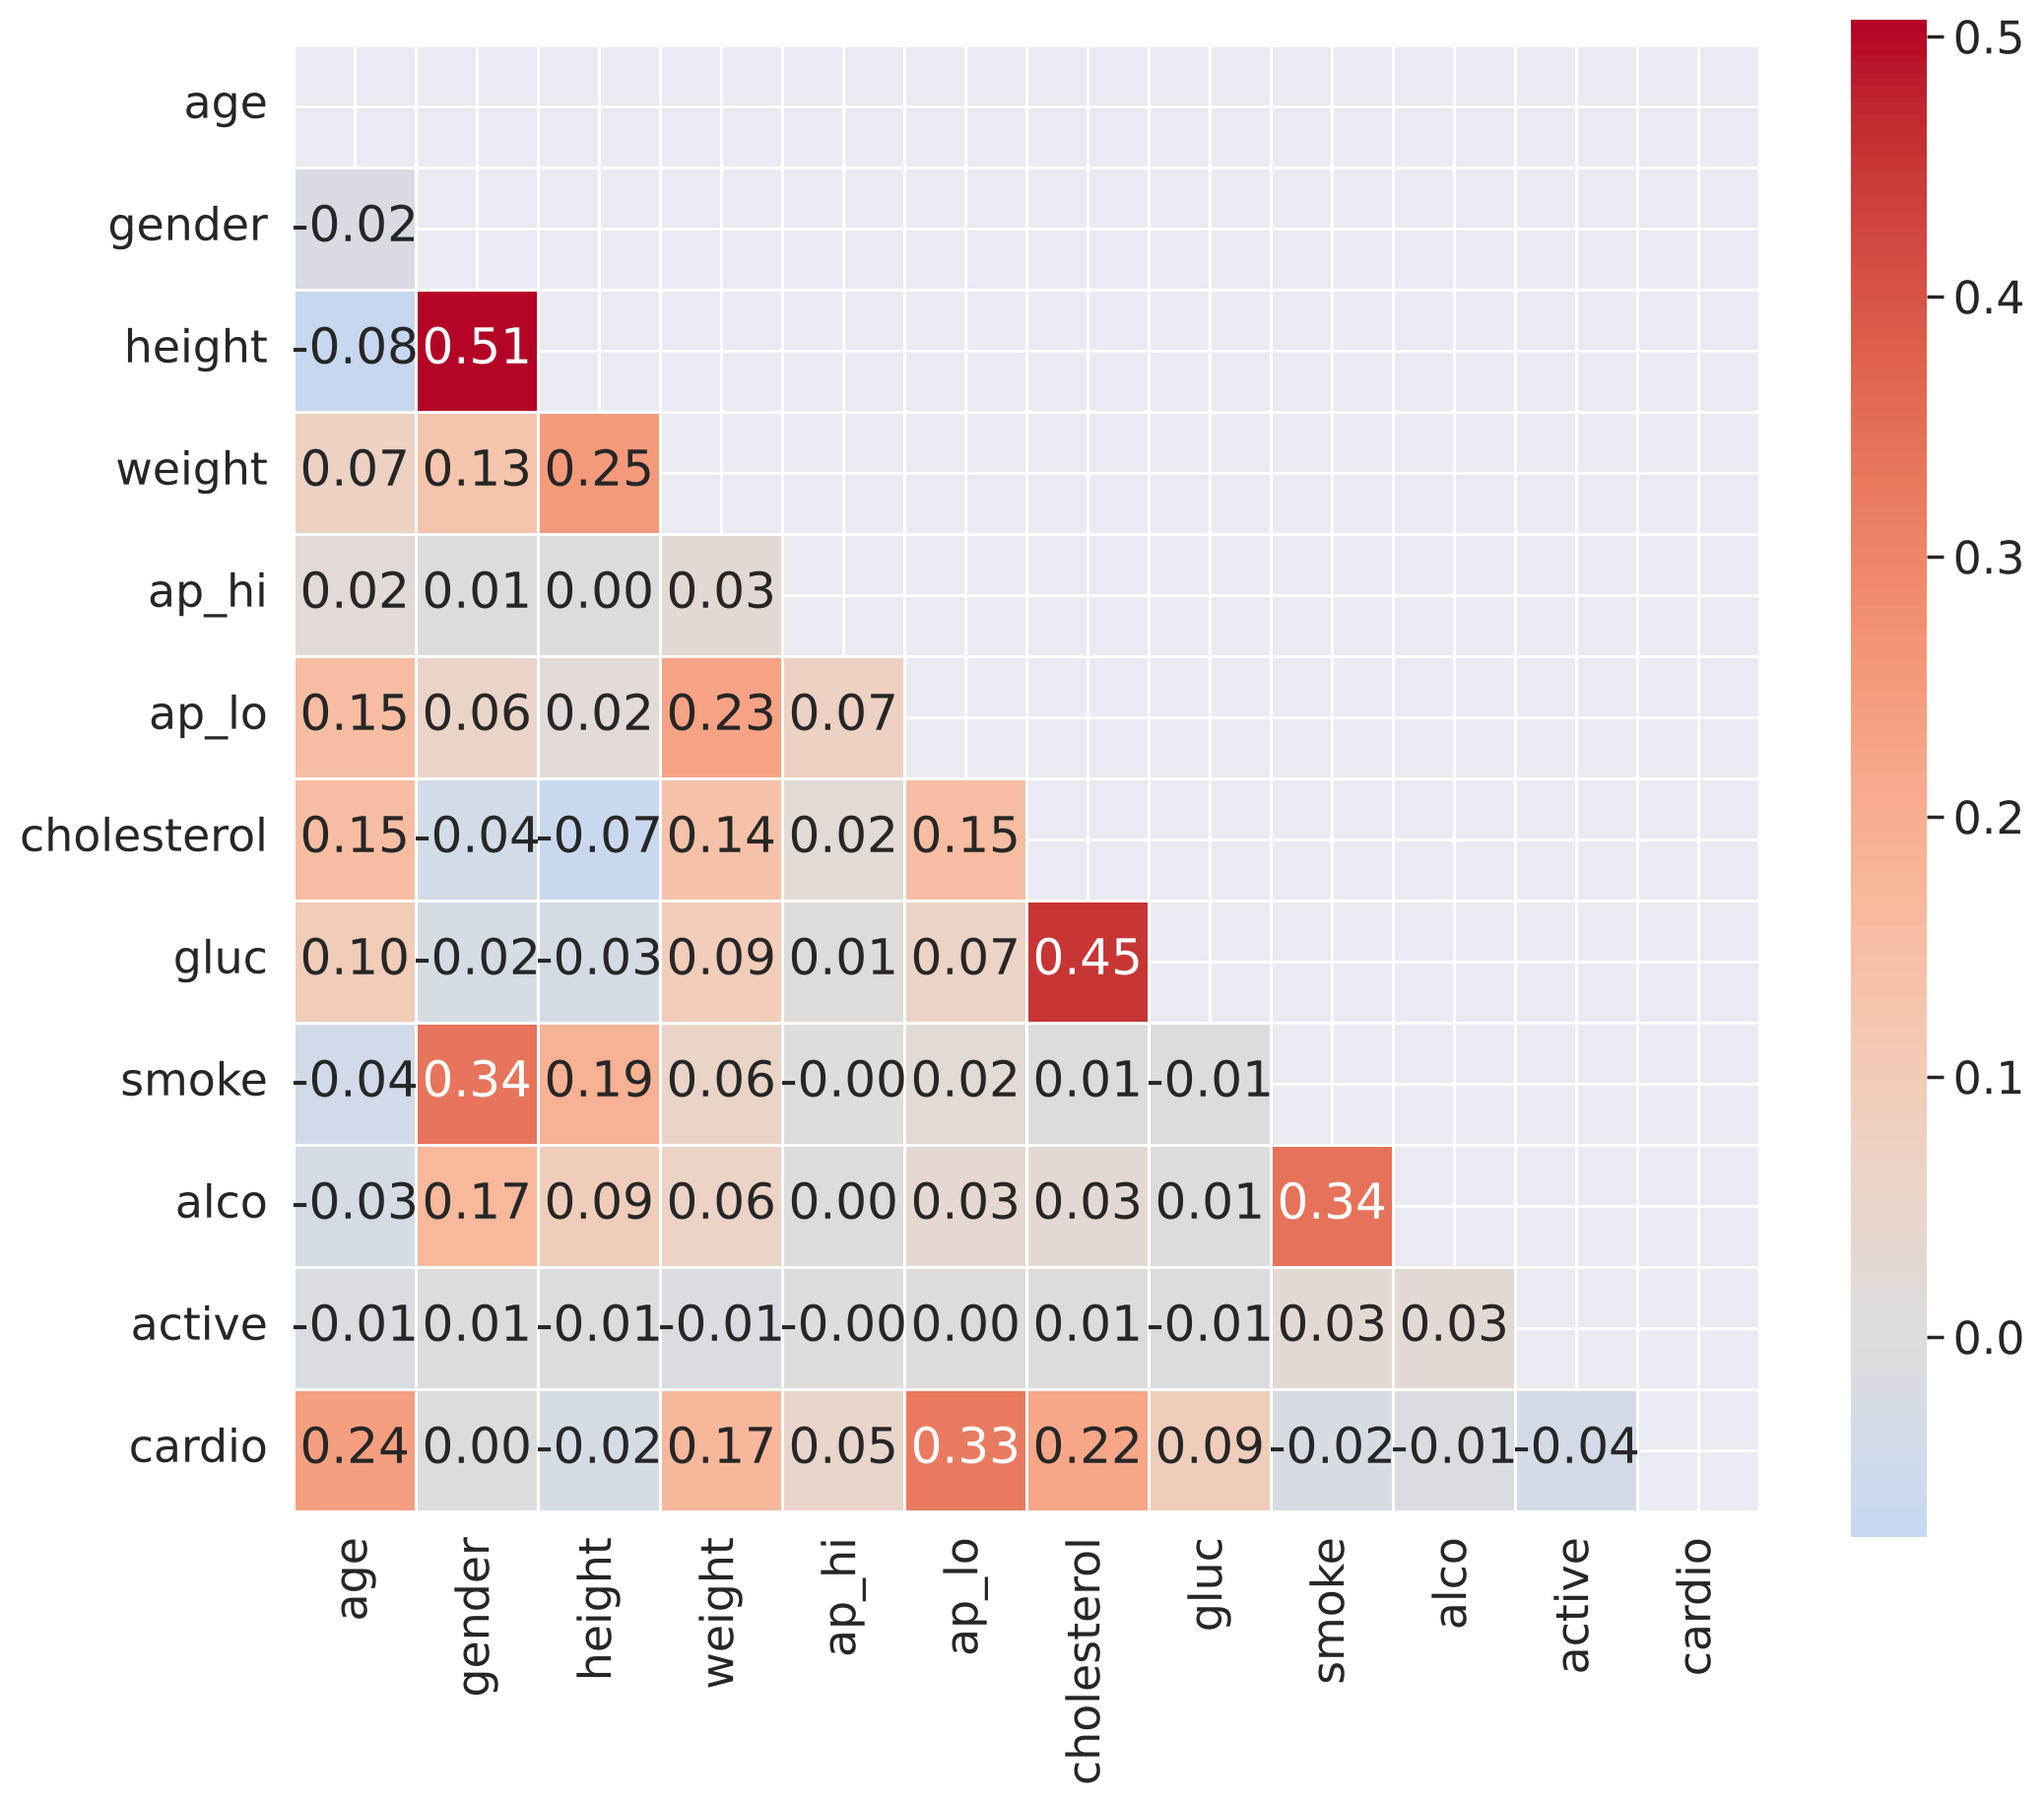

In [18]:
corr = filtered_df.drop(columns=["id", "age_years", "BMI"]).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(12, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5);

In [19]:
corr["gender"].drop("gender").sort_values(key=abs, ascending=False)

height         0.506447
smoke          0.337855
alco           0.168887
weight         0.130193
ap_lo          0.059743
cholesterol   -0.038817
gluc          -0.023243
age           -0.018320
active         0.007791
ap_hi          0.005063
cardio         0.002349
Name: gender, dtype: float64

**Question 2.1. (1 point).** Which pair of features has the strongest Pearson's correlation with the *gender* feature?

1. Cardio, Cholesterol
2. Height, Smoke
3. Smoke, Alco
4. Height, Weight

### 2.2. Height distribution of men and women

From our exploration of the unique values earlier, we know that the gender is encoded by the values *1* and *2*. Although you do not know the mapping of these values to gender, you can figure that out graphically by looking at the mean values of height and weight for each value of the *gender* feature.

Create a violin plot for the height and gender using [`violinplot()`](https://seaborn.pydata.org/generated/seaborn.violinplot.html). Use the parameters:
- `hue` to split by gender;
- `scale` to evaluate the number of records for each gender.

In order for the plot to render correctly, you need to convert your `DataFrame` to *long* format using the `melt()` function from `pandas`.

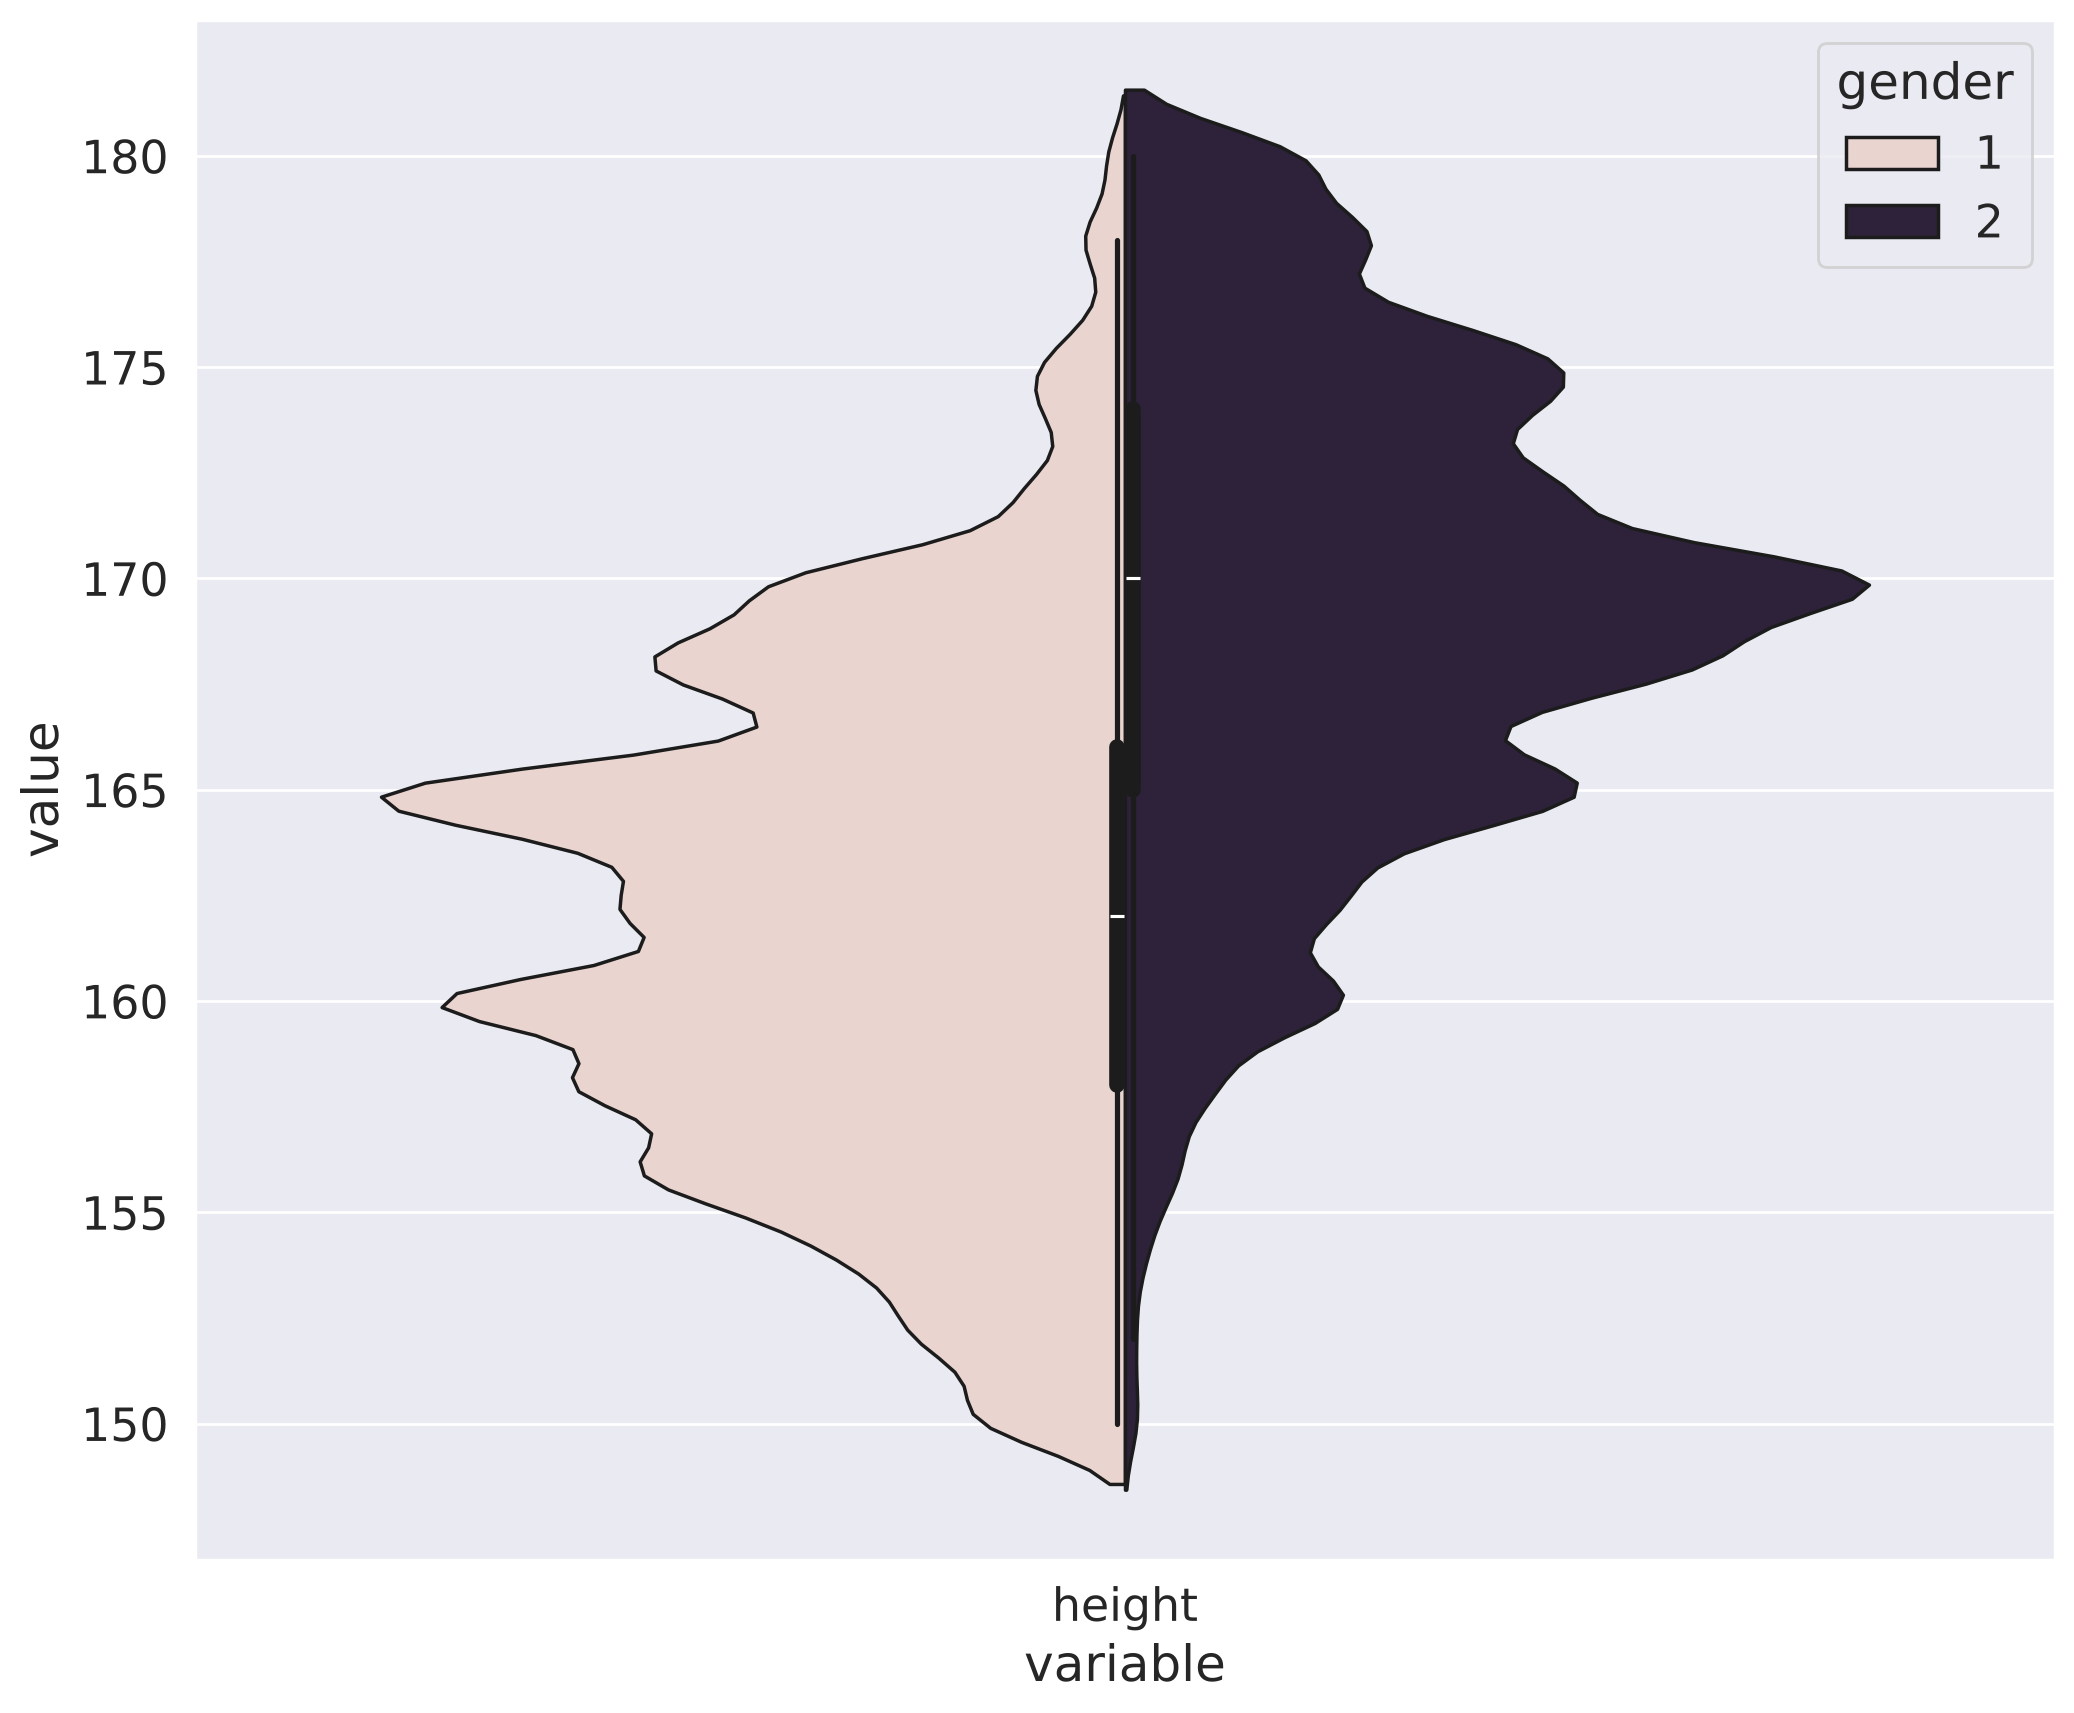

In [20]:
height_long = pd.melt(filtered_df, value_vars=["height"], id_vars=["gender"])
plt.figure(figsize=(12, 10))
sns.violinplot(x="variable", y="value", hue="gender", data=height_long, split=True, density_norm="count");

### 2.3. Rank correlation

In most cases, *the Pearson coefficient of linear correlation* is more than enough to discover patterns in data. But let's go a little further and calculate a [rank correlation](https://en.wikipedia.org/wiki/Rank_correlation). It will help us to identify such feature pairs in which the lower rank in the variational series of one feature always precedes the higher rank in the another one (and we have the opposite in the case of negative correlation).

Calculate and plot a correlation matrix using the [Spearman's rank correlation coefficient](https://en.wikipedia.org/wiki/Spearman%27s_rank_correlation_coefficient).

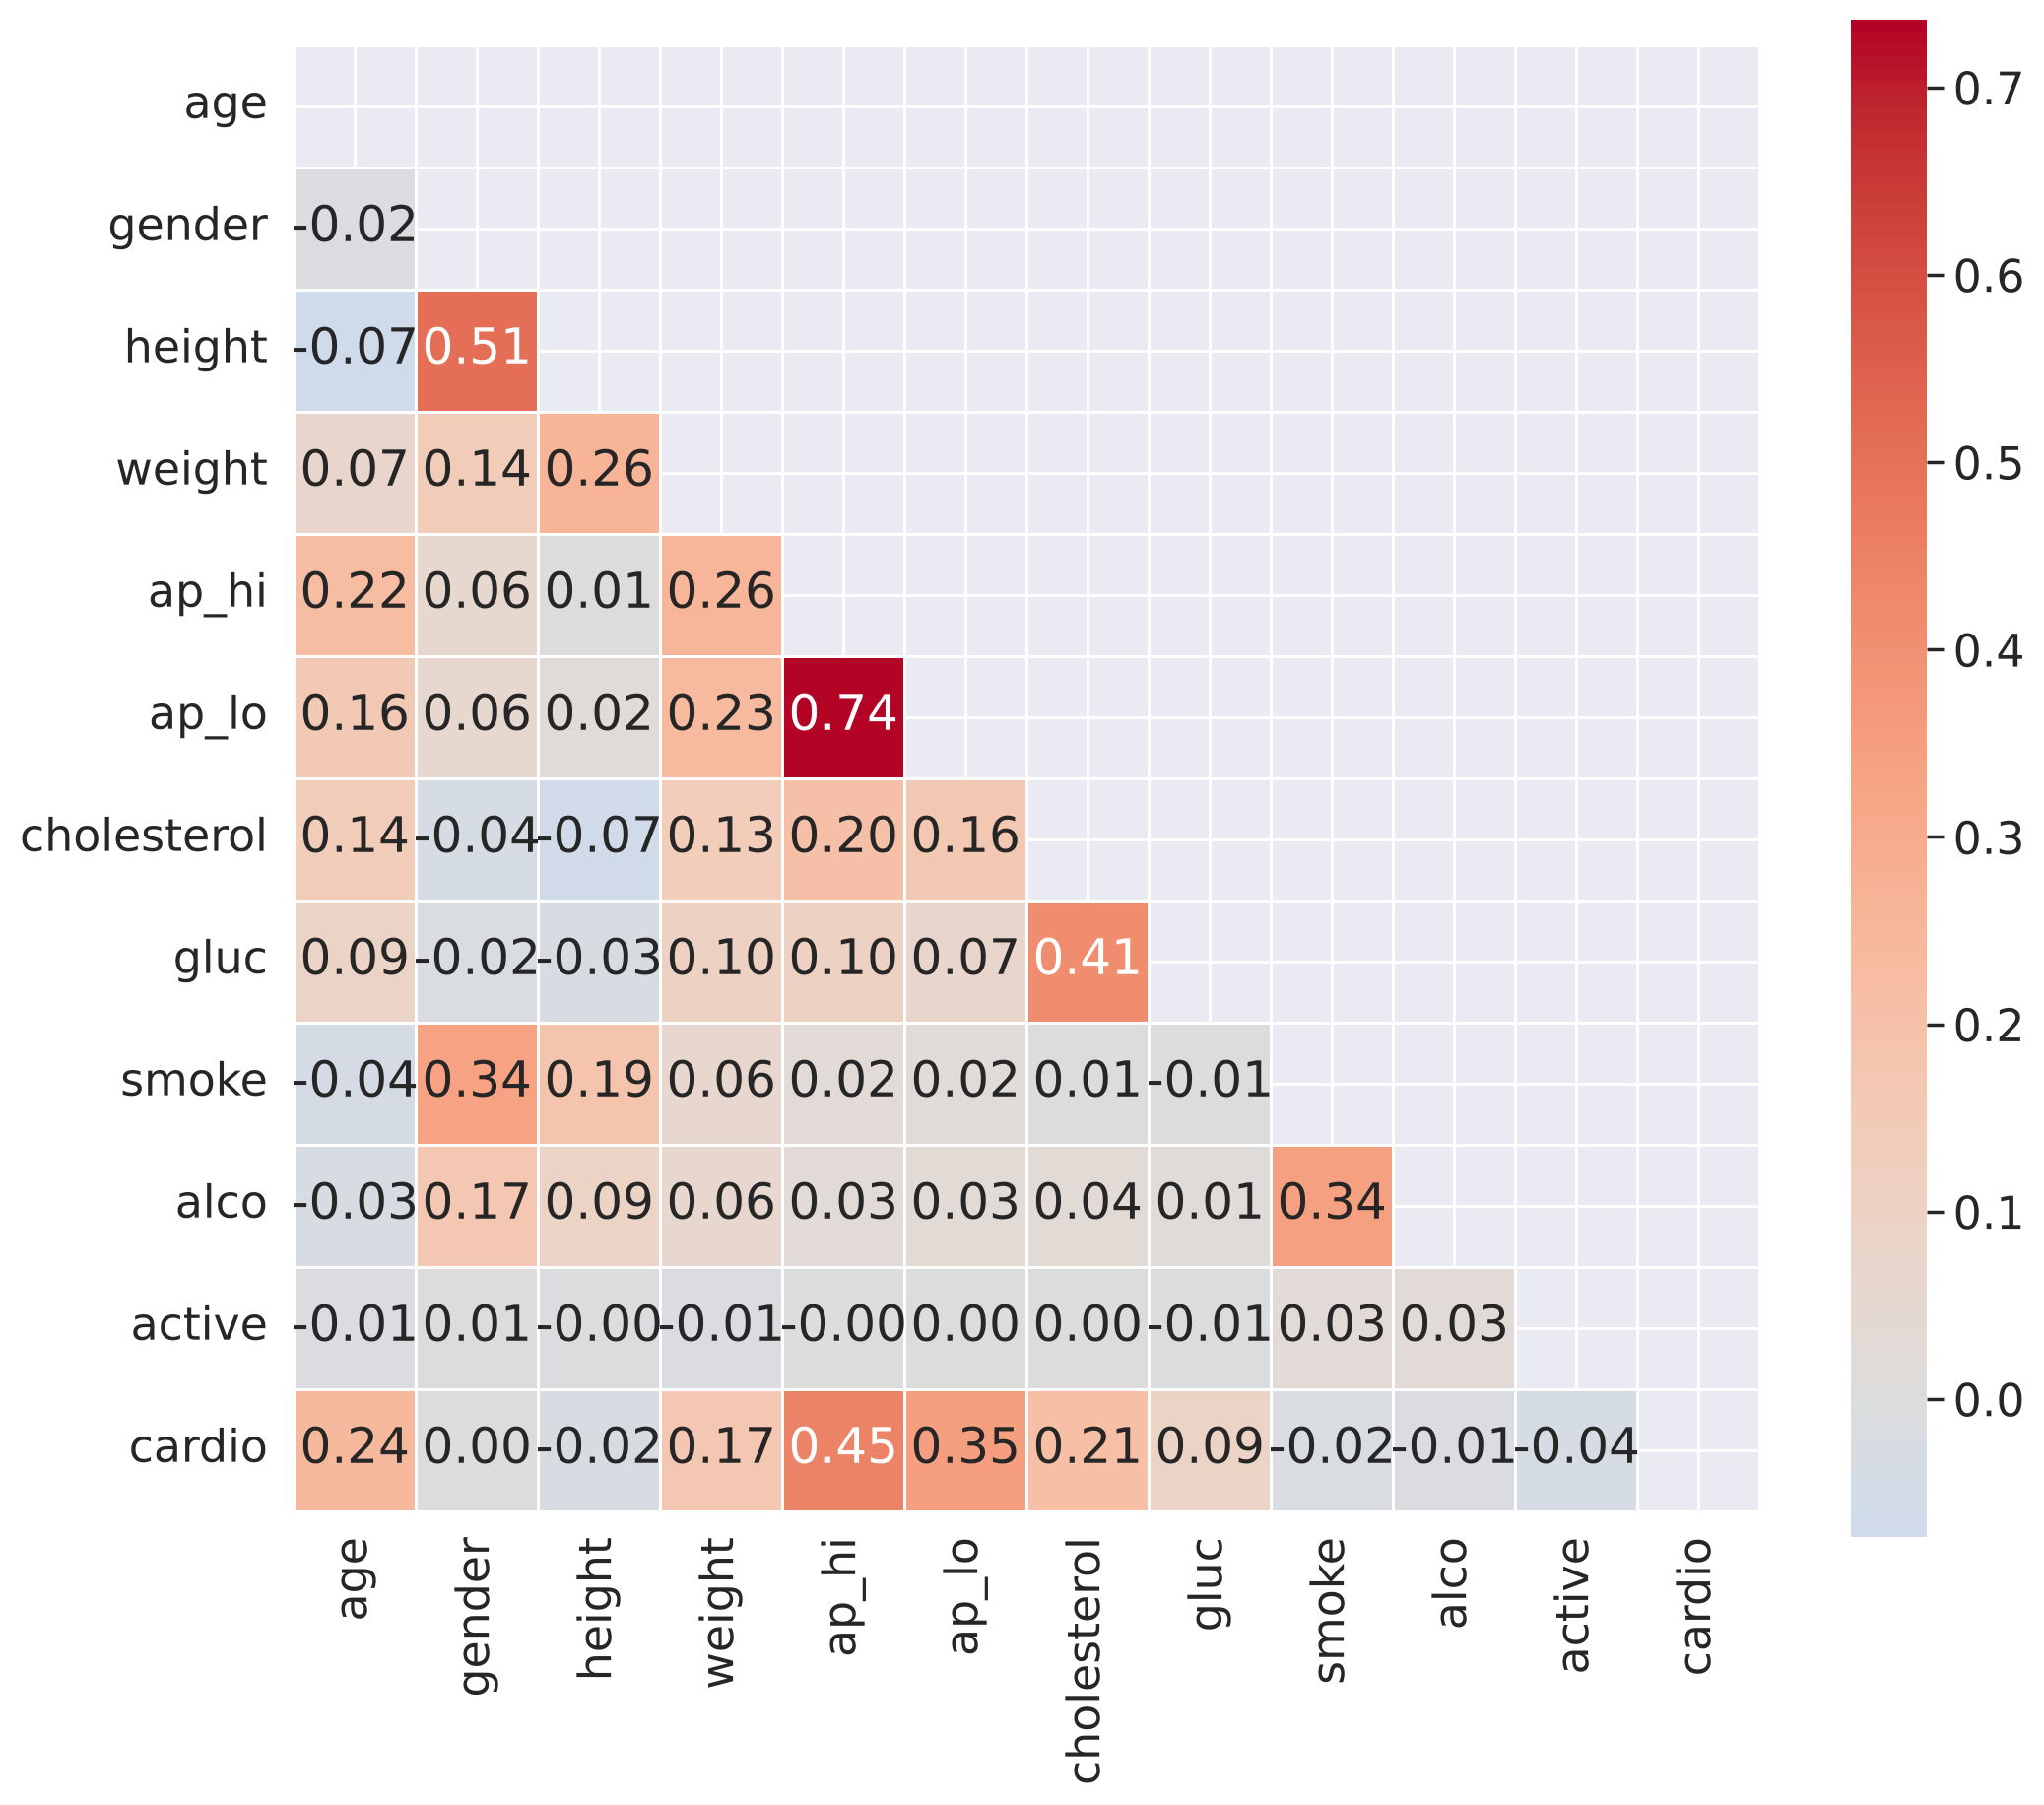

In [21]:
spearman = filtered_df.drop(columns=["id", "age_years", "BMI"]).corr(method="spearman")
mask = np.triu(np.ones_like(spearman, dtype=bool))
plt.figure(figsize=(12, 10))
sns.heatmap(spearman, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5);

In [22]:
pairs = spearman.where(~np.tril(np.ones_like(spearman, dtype=bool))).stack()
pairs.sort_values(key=abs, ascending=False).head(5)

ap_hi        ap_lo     0.736208
gender       height    0.510813
ap_hi        cardio    0.447185
cholesterol  gluc      0.407645
ap_lo        cardio    0.350219
dtype: float64

**Question 2.2. (1 point).** Which pair of features has the strongest Spearman rank correlation?

1. Height, Weight
2. Age, Weight
3. Cholesterol, Gluc
4. Cardio, Cholesterol
5. Ap_hi, Ap_lo
6. Smoke, Alco

**Question 2.3. (1 point).** Why do these features have strong rank correlation?

1. Inaccuracies in the data (data acquisition errors).
2. Relation is wrong, these features should not be related like that.
3. Nature of the data.

### 2.4. Age

Previously, we calculated the age of the respondents in years at the moment of examination.

Create a *count plot* using [`countplot()`](http://seaborn.pydata.org/generated/seaborn.countplot.html) with the age on the *X* axis and the number of people on the *Y* axis. Your resulting plot should have two columns for each age, corresponding to the number of people for each *cardio* class of that age.

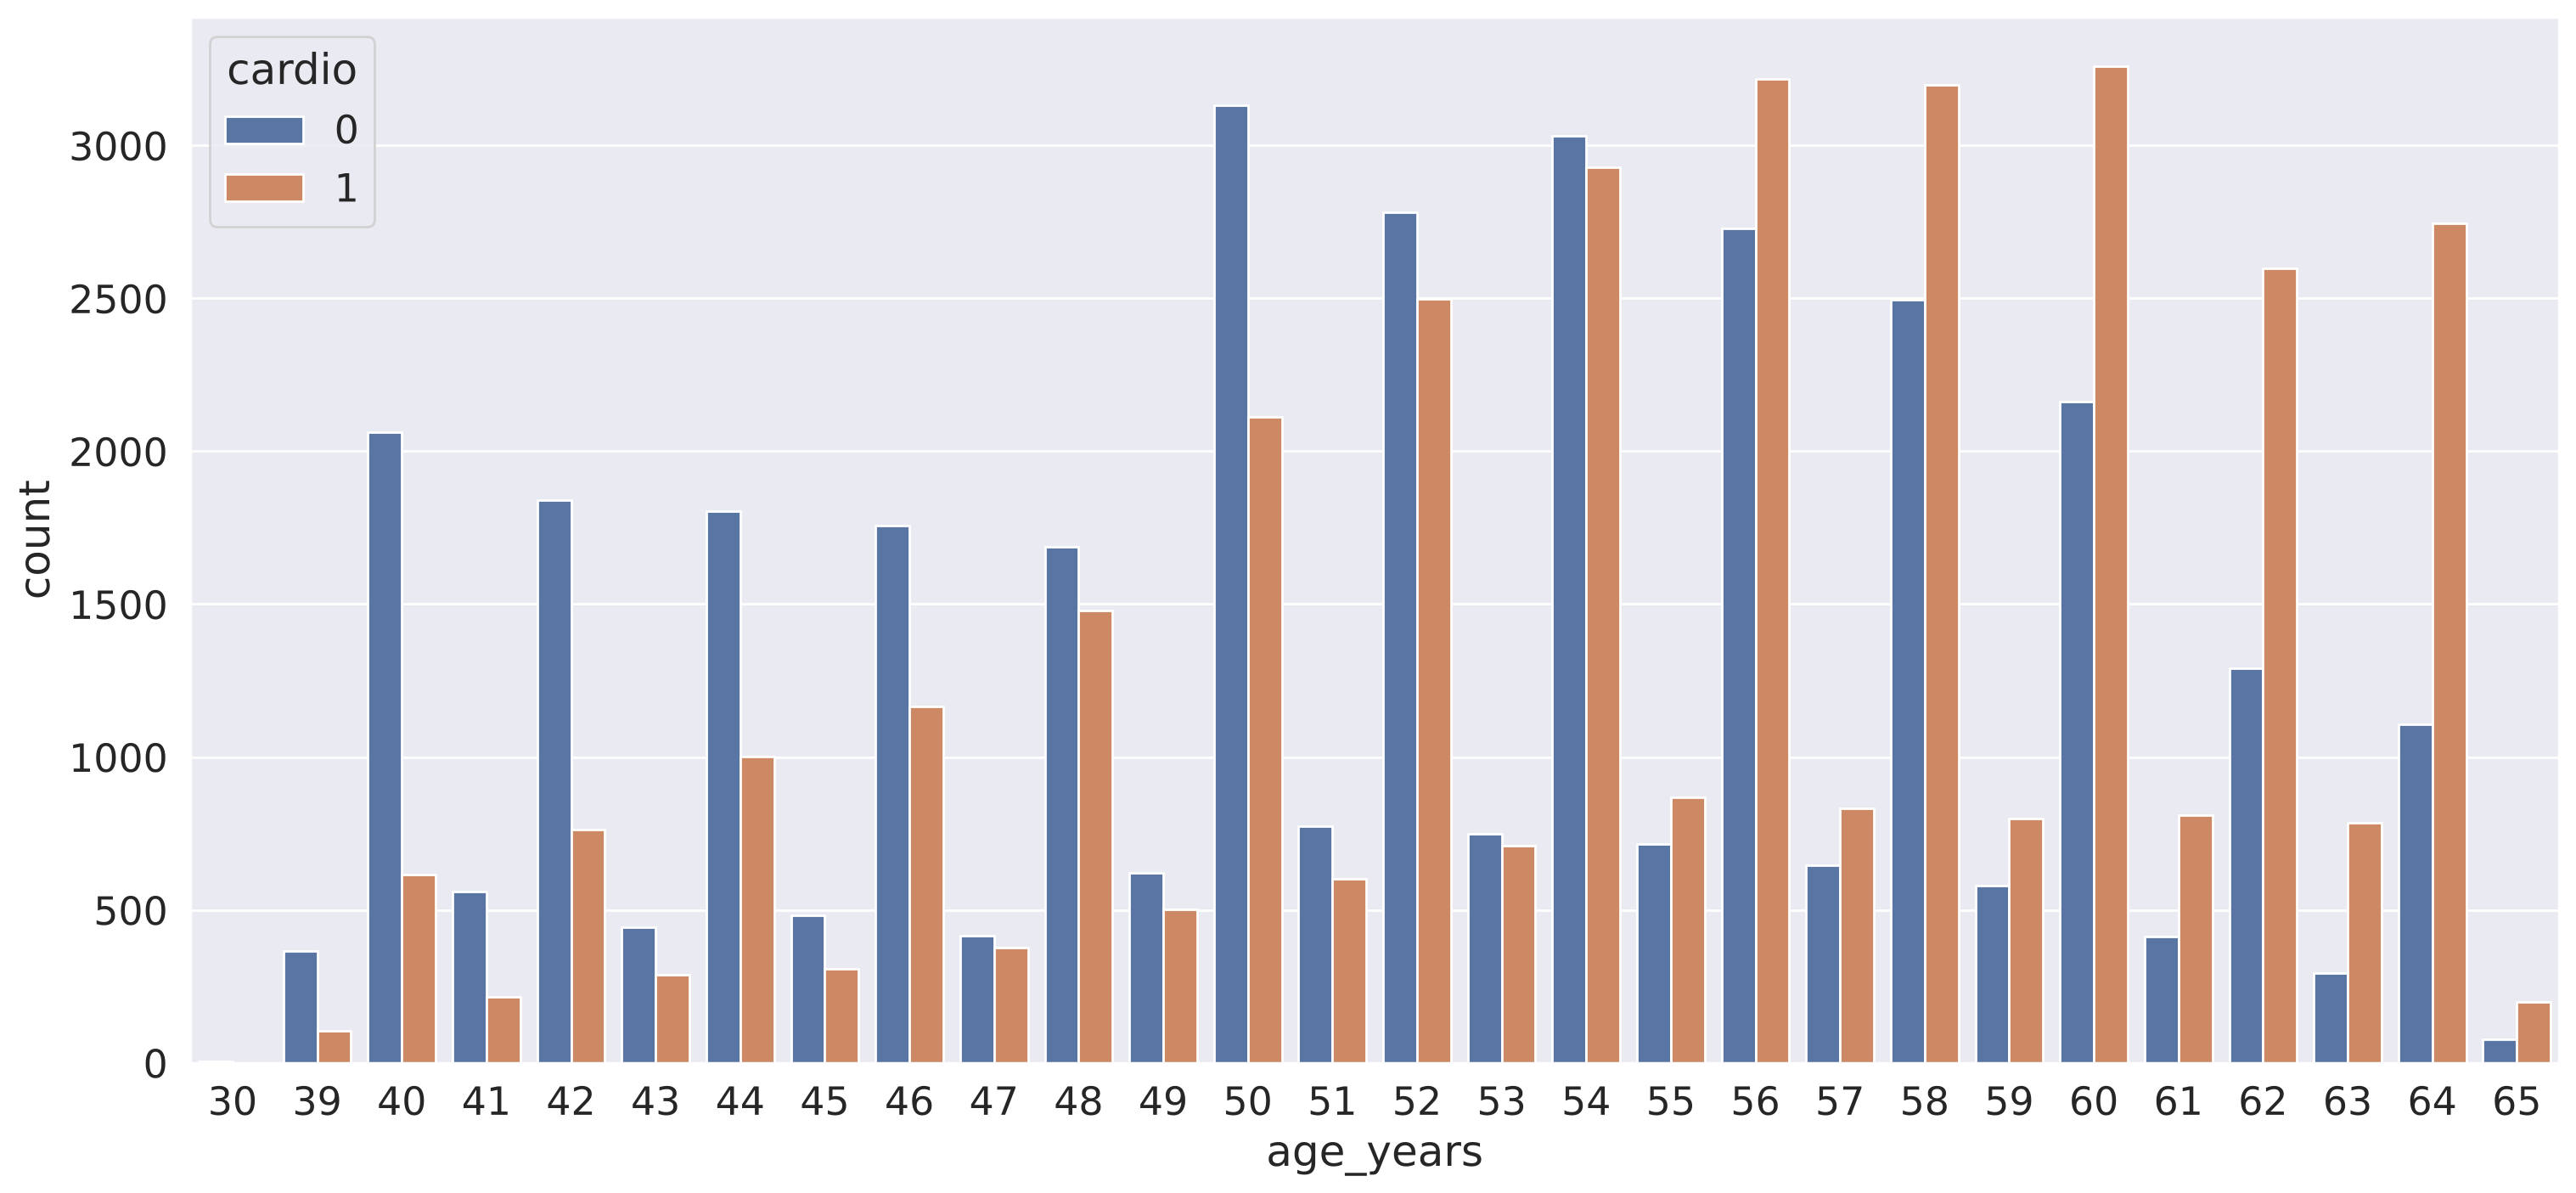

In [23]:
plt.figure(figsize=(18, 8))
sns.countplot(x="age_years", hue="cardio", data=df);

In [24]:
counts = pd.crosstab(df["age_years"], df["cardio"])
counts[counts[1] > counts[0]].index.min()

np.int64(55)

**Question 2.4. (1 point).** What is the smallest age at which the number of people with CVD outnumbers the number of people without CVD?

1. 44
2. 55
3. 64
4. 70